In [22]:
import pandas as pd
import numpy as np

import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import mean_absolute_error,mean_squared_error,r2_score
import statsmodels.api as sm

#### Schema definition

In [23]:
column_names = [
    "Sex",             # Kategorik: M, F, I
    "Length",          # Sayısal (float)
    "Diameter",        # Sayısal (float)
    "Height",          # Sayısal (float)
    "Whole_weight",    # Sayısal (float)
    "Shucked_weight",  # Sayısal (float)
    "Viscera_weight",  # Sayısal (float)
    "Shell_weight",    # Sayısal (float)
    "Rings"            # Hedef değişken (int) - tahmin edeceğimiz değer
]
df= pd.read_csv("abalone.data",header=None,names=column_names)
df["Age"] = df["Rings"]+1.5
df.head(2)

,Sex,Length,Diameter,Height,Whole_weight,Shucked_weight,Viscera_weight,Shell_weight,Rings,Age
0,M,0.455,0.365,0.095,0.5140,0.2245,0.1010,0.15,15,16.5
1,M,0.350,0.265,0.090,0.2255,0.0995,0.0485,0.07,7,8.5


#### Veri seti hakkında bilgiler edinelim

In [24]:
print("VEri seti boyutu: ", df.shape)
df.info()

VEri seti boyutu:  (4177, 10)
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 4177 entries, 0 to 4176
Data columns (total 10 columns):
 #   Column          Non-Null Count  Dtype  
---  ------          --------------  -----  
 0   Sex             4177 non-null   object 
 1   Length          4177 non-null   float64
 2   Diameter        4177 non-null   float64
 3   Height          4177 non-null   float64
 4   Whole_weight    4177 non-null   float64
 5   Shucked_weight  4177 non-null   float64
 6   Viscera_weight  4177 non-null   float64
 7   Shell_weight    4177 non-null   float64
 8   Rings           4177 non-null   int64  
 9   Age             4177 non-null   float64
dtypes: float64(8), int64(1), object(1)
memory usage: 326.5+ KB


In [25]:
df.describe().T

,count,mean,std,min,25%,50%,75%,max
Length,4177.0,0.523992,0.120093,0.0750,0.4500,0.5450,0.615,0.8150
Diameter,4177.0,0.407881,0.099240,0.0550,0.3500,0.4250,0.480,0.6500
Height,4177.0,0.139516,0.041827,0.0000,0.1150,0.1400,0.165,1.1300
Whole_weight,4177.0,0.828742,0.490389,0.0020,0.4415,0.7995,1.153,2.8255
Shucked_weight,4177.0,0.359367,0.221963,0.0010,0.1860,0.3360,0.502,1.4880
Viscera_weight,4177.0,0.180594,0.109614,0.0005,0.0935,0.1710,0.253,0.7600
Shell_weight,4177.0,0.238831,0.139203,0.0015,0.1300,0.2340,0.329,1.0050
Rings,4177.0,9.933684,3.224169,1.0000,8.0000,9.0000,11.000,29.0000
Age,4177.0,11.433684,3.224169,2.5000,9.5000,10.5000,12.500,30.5000


In [26]:
df["Sex"].value_counts()

Sex
M    1528
I    1342
F    1307
Name: count, dtype: int64

#### Veriyi görselleştirelim

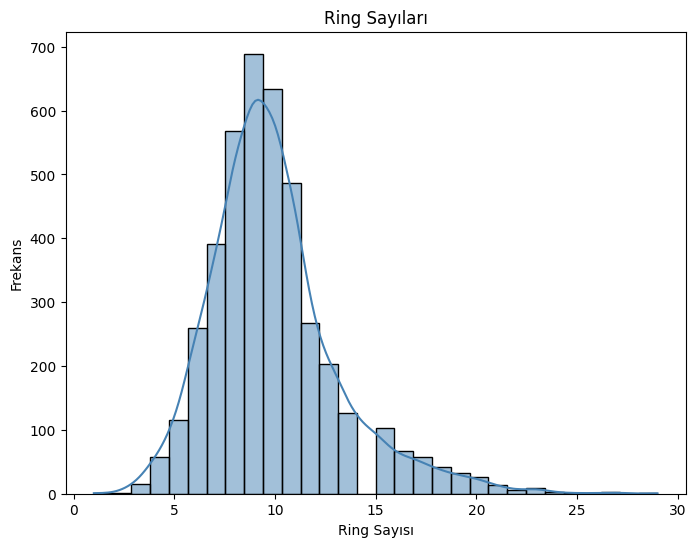

In [27]:
plt.figure(figsize=(8,6))
sns.histplot(df["Rings"],bins=30,kde= True, color ="steelblue")

plt.title("Ring Sayıları")
plt.xlabel("Ring Sayısı")
plt.ylabel("Frekans")

plt.show()

#### Şu korelasyon matrisiyle bir bakalım sütunların birbiriyle ilişkisi neymiş

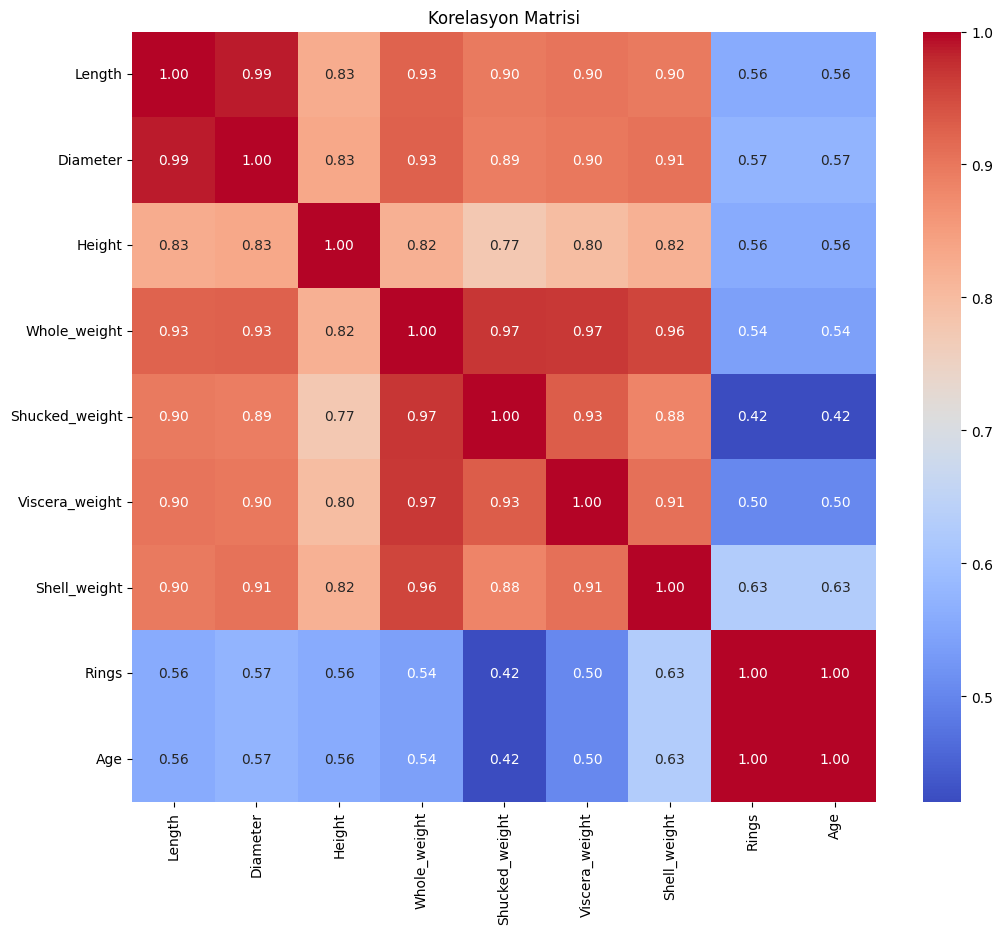

In [28]:
numeric_cols = df.select_dtypes(include=[np.number])
corr_matrix = numeric_cols.corr()
plt.figure(figsize=(12, 10
                    ))
sns.heatmap(corr_matrix, annot=True, cmap="coolwarm", fmt=".2f")
plt.title("Korelasyon Matrisi")
plt.show()

#### One hot encoding yapalım

In [29]:
df_encoded = pd.get_dummies(df, columns=["Sex"], drop_first=True)
df_encoded["Sex_I"] = df_encoded["Sex_I"].astype(int)
df_encoded["Sex_M"] = df_encoded["Sex_M"].astype(int)

In [30]:
df_encoded

,Length,Diameter,Height,Whole_weight,Shucked_weight,Viscera_weight,Shell_weight,Rings,Age,Sex_I,Sex_M
0,0.455,0.365,0.095,0.5140,0.2245,0.1010,0.1500,15,16.5,0,1
1,0.350,0.265,0.090,0.2255,0.0995,0.0485,0.0700,7,8.5,0,1
2,0.530,0.420,0.135,0.6770,0.2565,0.1415,0.2100,9,10.5,0,0
3,0.440,0.365,0.125,0.5160,0.2155,0.1140,0.1550,10,11.5,0,1
4,0.330,0.255,0.080,0.2050,0.0895,0.0395,0.0550,7,8.5,1,0
...,...,...,...,...,...,...,...,...,...,...,...
4172,0.565,0.450,0.165,0.8870,0.3700,0.2390,0.2490,11,12.5,0,0
4173,0.590,0.440,0.135,0.9660,0.4390,0.2145,0.2605,10,11.5,0,1
4174,0.600,0.475,0.205,1.1760,0.5255,0.2875,0.3080,9,10.5,0,1
4175,0.625,0.485,0.150,1.0945,0.5310,0.2610,0.2960,10,11.5,0,0


#### Değişkenleri belirleyelim

In [31]:
X = df_encoded.drop(columns = ["Rings", "Age"])
y = df_encoded["Rings"]

#### Train - test'i split edelim

In [32]:
X_train,X_test,y_train,y_test = train_test_split(X,y,test_size=0.2,random_state=42)

#### modele geçelim

In [33]:
model = LinearRegression()
model.fit(X_train,y_train)
model_pred = model.predict(X_test)


#### hata hesaplama

In [34]:
r2_multi = r2_score(y_test,model_pred)
print("R-squared değeri (Çoklu Doğrusal Regresyon):", r2_multi)
mae = mean_absolute_error(y_test,model_pred)
print("Ortalama Mutlak Hata (MAE):", mae)
mse = mean_squared_error(y_test,model_pred)
print("Ortalama Kare Hata (MSE):", mse)
rmse = np.sqrt(mse)
print("Kök Ortalama Kare Hata (RMSE):", rmse)
#

R-squared değeri (Çoklu Doğrusal Regresyon): 0.5481628137889263
Ortalama Mutlak Hata (MAE): 1.5931067816608362
Ortalama Kare Hata (MSE): 4.891232447128579
Kök Ortalama Kare Hata (RMSE): 2.2116130871218362


####OLS bakalım

In [35]:
X_train_sm = sm.add_constant(X_train)
model_sm = sm.OLS(y_train,X_train_sm)
results = model_sm.fit()
print(results.summary())


                            OLS Regression Results                            
Dep. Variable:                  Rings   R-squared:                       0.535
Model:                            OLS   Adj. R-squared:                  0.534
Method:                 Least Squares   F-statistic:                     425.5
Date:                Sun, 27 Sep 2026   Prob (F-statistic):               0.00
Time:                        21:12:47   Log-Likelihood:                -7355.4
No. Observations:                3341   AIC:                         1.473e+04
Df Residuals:                    3331   BIC:                         1.479e+04
Df Model:                           9                                         
Covariance Type:            nonrobust                                         
                     coef    std err          t      P>|t|      [0.025      0.975]
----------------------------------------------------------------------------------
const              3.7435      0.330     11.

#### gerçek vs tahmin

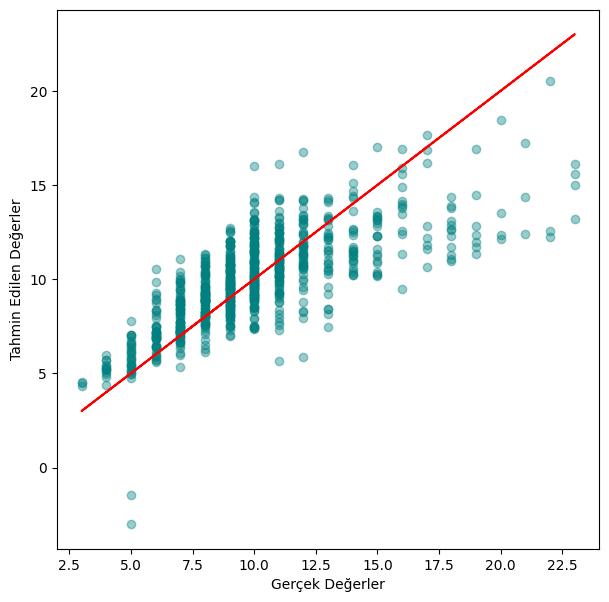

In [36]:
plt.figure(figsize=(7,7))
plt.scatter(y_test,model_pred,alpha=0.4,color="teal")
plt.plot(y_test,y_test,"r")
plt.xlabel("Gerçek Değerler")
plt.ylabel("Tahmin Edilen Değerler")
plt.show()

#### artıklara bakalım

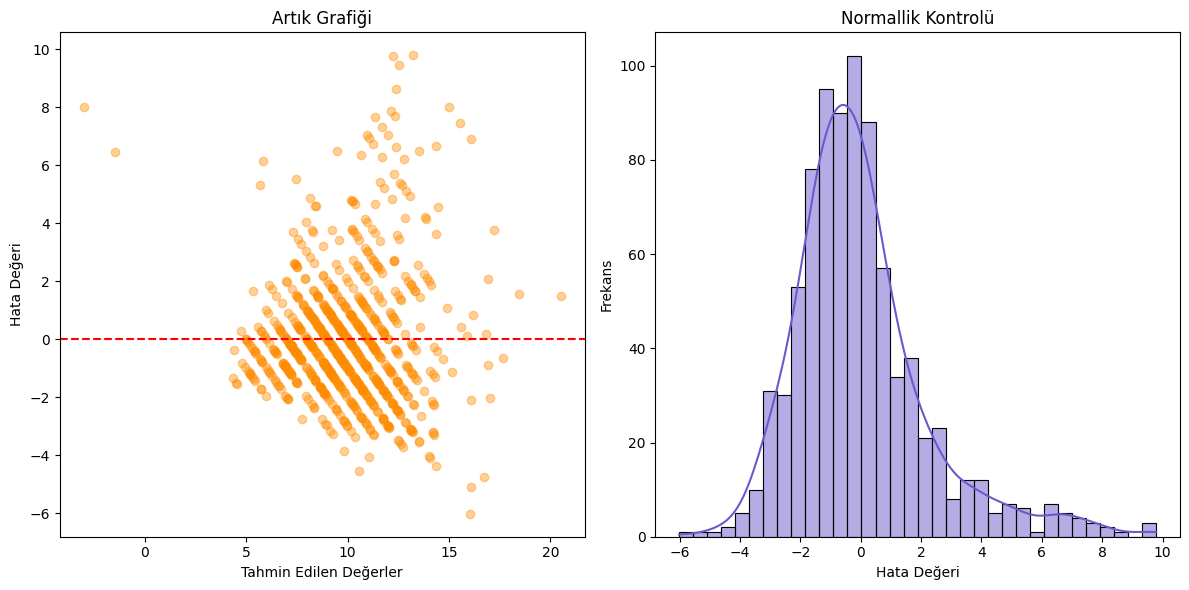

In [37]:
residual = y_test-model_pred
fig, axes = plt.subplots(1,2,figsize=(12,6))
axes[0].scatter(model_pred,residual,alpha=0.4,color="darkorange")
axes[0].axhline(y=0,color="red",linestyle="--")
axes[0].set_xlabel("Tahmin Edilen Değerler")
axes[0].set_ylabel("Hata Değeri")
axes[0].set_title("Artık Grafiği")
sns.histplot(residual,kde=True,ax=axes[1],color="slateblue")
axes[1].set_title("Normallik Kontrolü")
axes[1].set_xlabel("Hata Değeri")
axes[1].set_ylabel("Frekans")
plt.tight_layout()
plt.show()

#### polinom regresyon tek değişkenle

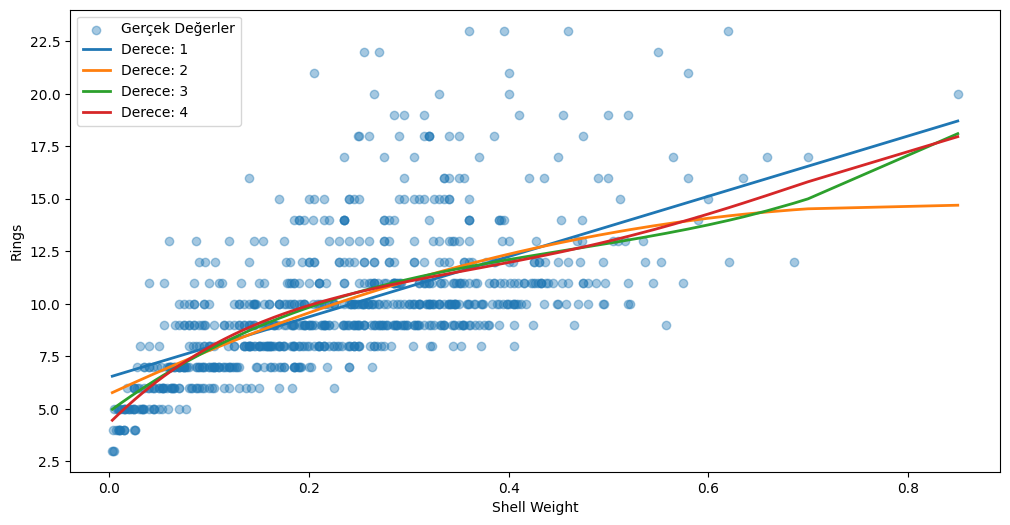

,R2,RMSE
Derece,,
1,0.400853,2.546741
2,0.414645,2.517259
3,0.426366,2.491928
4,0.429181,2.485808


In [38]:
from sklearn.preprocessing import PolynomialFeatures
from sklearn.pipeline import make_pipeline

degrees = [1,2,3,4]
poly_results = {}

X_one_train = X_train[["Shell_weight"]]
X_one_test = X_test[["Shell_weight"]]
x_sorted = pd.DataFrame({"Shell_weight":np.sort(X_one_test["Shell_weight"].values)})

plt.figure(figsize=(12,6))
plt.scatter(X_one_test["Shell_weight"],y_test,alpha=0.4,color="#1f77b4",label="Gerçek Değerler")
for degree in degrees:
    model_poly = make_pipeline(PolynomialFeatures(degree),LinearRegression())
    model_poly.fit(X_one_train,y_train)
    poly_pred = model_poly.predict(X_one_test)
    poly_results[degree] = {
        "R2": r2_score(y_test,poly_pred),
        "RMSE": np.sqrt(mean_squared_error(y_test,poly_pred))
    }
    plt.plot(x_sorted["Shell_weight"],model_poly.predict(x_sorted),linewidth=2,label=f"Derece: {degree}")
plt.xlabel("Shell Weight")
plt.ylabel("Rings")
plt.legend()
plt.show()

pd.DataFrame(poly_results).T.rename_axis("Derece")

#### polinom regresyon tüm değişkenlerle

In [39]:
poly_features = PolynomialFeatures(degree=2)
X_poly_train = poly_features.fit_transform(X_train)
X_poly_test = poly_features.transform(X_test)

poly_multi_model = LinearRegression()
poly_multi_model.fit(X_poly_train,y_train)
poly_multi_pred = poly_multi_model.predict(X_poly_test)

r2_poly = r2_score(y_test,poly_multi_pred)
print("R-squared değeri (Polinom):", r2_poly)
mae_poly = mean_absolute_error(y_test,poly_multi_pred)
print("Ortalama Mutlak Hata (MAE):", mae_poly)
rmse_poly = np.sqrt(mean_squared_error(y_test,poly_multi_pred))
print("Kök Ortalama Kare Hata (RMSE):", rmse_poly)

R-squared değeri (Polinom): 0.5538221504793437
Ortalama Mutlak Hata (MAE): 1.538464509633029
Kök Ortalama Kare Hata (RMSE): 2.1977190308900454


#### logistic regresyon: german credit

In [40]:
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (confusion_matrix,ConfusionMatrixDisplay,accuracy_score,precision_score,
recall_score,f1_score,classification_report,roc_curve,roc_auc_score)

In [41]:
column_names = [
    "Checking_account_status",
    "Duration_months",
    "Credit_history",
    "Purpose",
    "Credit_amount",
    "Savings_account",
    "Employment_since",
    "Installment_rate",
    "Personal_status_sex",
    "Other_debtors",
    "Present_residence_since",
    "Property",
    "Age",
    "Other_installment_plans",
    "Housing",
    "Existing_credits",
    "Job",
    "People_liable",
    "Telephone",
    "Foreign_worker",
    "Target"
]
df = pd.read_csv("german.data",sep=r"\s+",header=None,names=column_names)
df.head(2)

,Checking_account_status,Duration_months,Credit_history,Purpose,Credit_amount,Savings_account,Employment_since,Installment_rate,Personal_status_sex,Other_debtors,...,Property,Age,Other_installment_plans,Housing,Existing_credits,Job,People_liable,Telephone,Foreign_worker,Target
0,A11,6,A34,A43,1169,A65,A75,4,A93,A101,...,A121,67,A143,A152,2,A173,1,A192,A201,1
1,A12,48,A32,A43,5951,A61,A73,2,A92,A101,...,A121,22,A143,A152,1,A173,1,A191,A201,2


In [42]:
print("Veri seti boyutu: ", df.shape)
df.info()

Veri seti boyutu:  (1000, 21)
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1000 entries, 0 to 999
Data columns (total 21 columns):
 #   Column                   Non-Null Count  Dtype 
---  ------                   --------------  ----- 
 0   Checking_account_status  1000 non-null   object
 1   Duration_months          1000 non-null   int64 
 2   Credit_history           1000 non-null   object
 3   Purpose                  1000 non-null   object
 4   Credit_amount            1000 non-null   int64 
 5   Savings_account          1000 non-null   object
 6   Employment_since         1000 non-null   object
 7   Installment_rate         1000 non-null   int64 
 8   Personal_status_sex      1000 non-null   object
 9   Other_debtors            1000 non-null   object
 10  Present_residence_since  1000 non-null   int64 
 11  Property                 1000 non-null   object
 12  Age                      1000 non-null   int64 
 13  Other_installment_plans  1000 non-null   object
 14  Housing    

In [43]:
df.describe().T

,count,mean,std,min,25%,50%,75%,max
Duration_months,1000.0,20.903,12.058814,4.0,12.0,18.0,24.00,72.0
Credit_amount,1000.0,3271.258,2822.736876,250.0,1365.5,2319.5,3972.25,18424.0
Installment_rate,1000.0,2.973,1.118715,1.0,2.0,3.0,4.00,4.0
Present_residence_since,1000.0,2.845,1.103718,1.0,2.0,3.0,4.00,4.0
Age,1000.0,35.546,11.375469,19.0,27.0,33.0,42.00,75.0
Existing_credits,1000.0,1.407,0.577654,1.0,1.0,1.0,2.00,4.0
People_liable,1000.0,1.155,0.362086,1.0,1.0,1.0,1.00,2.0
Target,1000.0,1.300,0.458487,1.0,1.0,1.0,2.00,2.0


#### hedefi 0/1 yapalım

In [44]:
df["Bad_risk"] = (df["Target"]==2).astype(int)
df = df.drop(columns=["Target"])
df["Bad_risk"].value_counts(normalize=True).rename(index={0:"İyi",1:"Kötü"})

Bad_risk
İyi     0.7
Kötü    0.3
Name: proportion, dtype: float64

C:\Users\emir\AppData\Local\Temp\ipykernel_38848\2452038248.py:2: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(x="Bad_risk",data=df,palette="pastel")


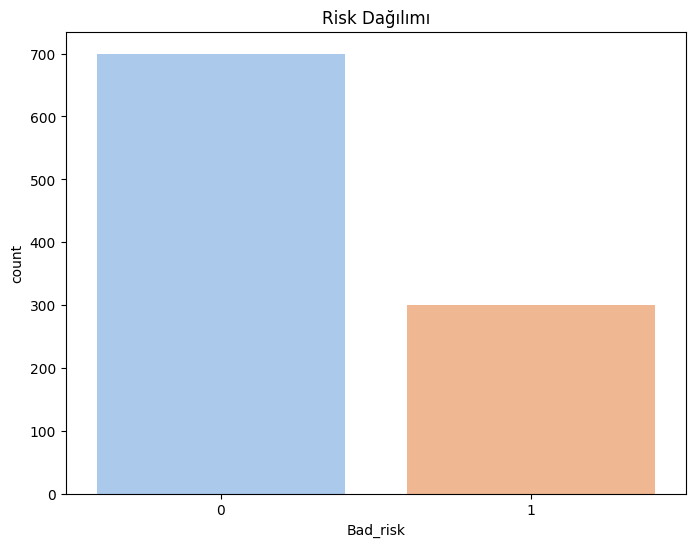

In [45]:
plt.figure(figsize=(8,6))
sns.countplot(x="Bad_risk",data=df,palette="pastel")
plt.title("Risk Dağılımı")
plt.xlabel("Bad_risk")
plt.show()

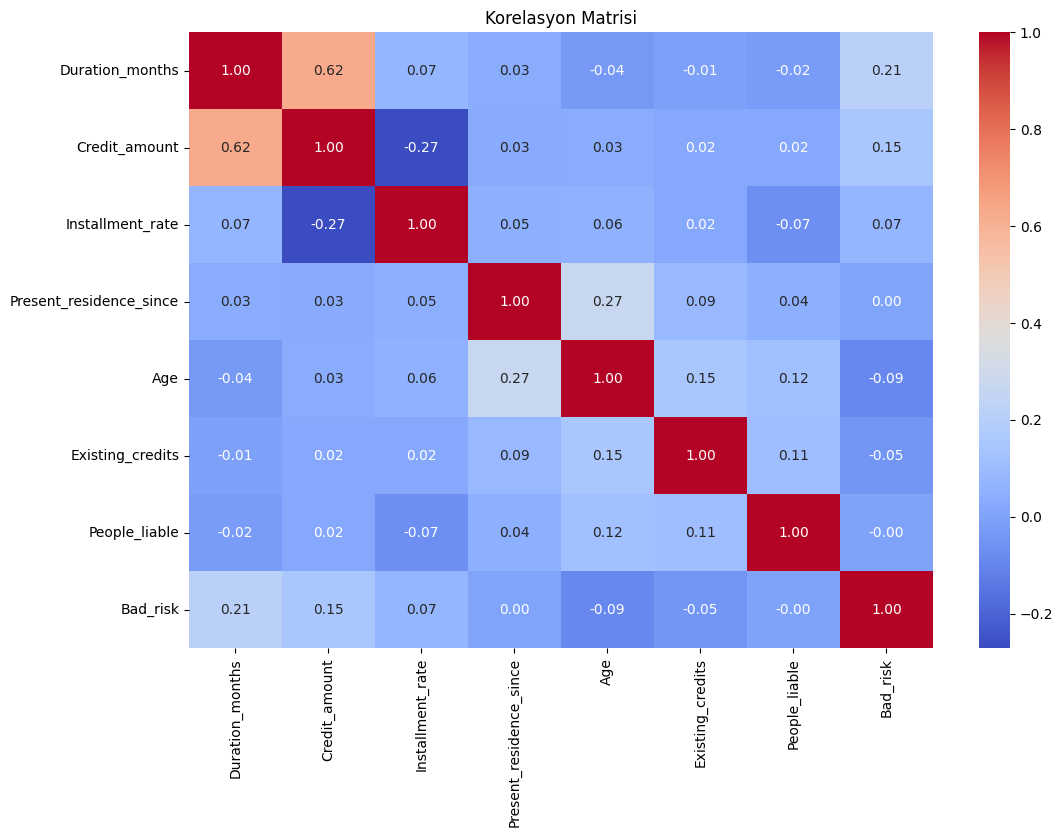

In [46]:
numeric_cols = df.select_dtypes(include=[np.number])
corr_matrix = numeric_cols.corr()
plt.figure(figsize=(12,8))
sns.heatmap(corr_matrix,annot=True,cmap="coolwarm",fmt=".2f")
plt.title("Korelasyon Matrisi")
plt.show()

#### One hot encoding yapalım

In [47]:
categorical_cols = df.select_dtypes(include="object").columns.tolist()
df_encoded = pd.get_dummies(df,columns=categorical_cols,drop_first=True,dtype=int)
df_encoded.head()

,Duration_months,Credit_amount,Installment_rate,Present_residence_since,Age,Existing_credits,People_liable,Bad_risk,Checking_account_status_A12,Checking_account_status_A13,...,Property_A124,Other_installment_plans_A142,Other_installment_plans_A143,Housing_A152,Housing_A153,Job_A172,Job_A173,Job_A174,Telephone_A192,Foreign_worker_A202
0,6,1169,4,4,67,2,1,0,0,0,...,0,0,1,1,0,0,1,0,1,0
1,48,5951,2,2,22,1,1,1,1,0,...,0,0,1,1,0,0,1,0,0,0
2,12,2096,2,3,49,1,2,0,0,0,...,0,0,1,1,0,1,0,0,0,0
3,42,7882,2,4,45,1,2,0,0,0,...,0,0,1,0,1,0,1,0,0,0
4,24,4870,3,4,53,2,2,1,0,0,...,1,0,1,0,1,0,1,0,0,0


#### Değişkenleri belirleyelim

In [48]:
X = df_encoded.drop(columns=["Bad_risk"])
y = df_encoded["Bad_risk"]

#### Train - test'i split edelim

In [49]:
X_train,X_test,y_train,y_test = train_test_split(X,y,test_size=0.2,random_state=42,stratify=y)

#### scale edelim

In [50]:
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

X_train_scaled = pd.DataFrame(X_train_scaled,columns=X_train.columns,index=X_train.index)
X_test_scaled = pd.DataFrame(X_test_scaled,columns=X_test.columns,index=X_test.index)
X_train_scaled.head()

,Duration_months,Credit_amount,Installment_rate,Present_residence_since,Age,Existing_credits,People_liable,Checking_account_status_A12,Checking_account_status_A13,Checking_account_status_A14,...,Property_A124,Other_installment_plans_A142,Other_installment_plans_A143,Housing_A152,Housing_A153,Job_A172,Job_A173,Job_A174,Telephone_A192,Foreign_worker_A202
828,1.289592,1.925766,0.052281,1.053413,1.057784,-0.718745,-0.436436,-0.604308,-0.260942,-0.808018,...,2.334869,-0.226381,0.482354,-1.574249,2.881376,-0.496091,0.752036,-0.409736,-0.82717,-0.200779
997,-0.742595,-0.892853,0.942164,1.053413,0.242449,-0.718745,-0.436436,-0.604308,-0.260942,1.237597,...,-0.428290,-0.226381,0.482354,0.635223,-0.347056,-0.496091,0.752036,-0.409736,-0.82717,-0.200779
148,1.289592,0.816433,0.052281,-0.747293,-0.663479,1.045047,-0.436436,-0.604308,-0.260942,-0.808018,...,-0.428290,-0.226381,0.482354,0.635223,-0.347056,-0.496091,0.752036,-0.409736,-0.82717,-0.200779
735,1.289592,0.299568,0.052281,-0.747293,-0.572886,-0.718745,-0.436436,1.654786,-0.260942,-0.808018,...,2.334869,-0.226381,-2.073165,0.635223,-0.347056,-0.496091,-1.329724,-0.409736,-0.82717,-0.200779
130,2.305686,1.982655,-1.727486,-0.747293,-1.025850,-0.718745,-0.436436,1.654786,-0.260942,-0.808018,...,-0.428290,-0.226381,0.482354,0.635223,-0.347056,-0.496091,0.752036,-0.409736,-0.82717,-0.200779


#### modele geçelim

In [51]:
log_reg = LogisticRegression(max_iter=1000)
log_reg.fit(X_train_scaled,y_train)

,penalty,'l2'
,dual,False
,tol,0.0001
,C,1.0
,fit_intercept,True
,intercept_scaling,1
,class_weight,None
,random_state,None
,solver,'lbfgs'
,max_iter,1000
,multi_class,'deprecated'


In [52]:
y_proba = log_reg.predict_proba(X_test_scaled)[:,1]
y_pred = log_reg.predict(X_test_scaled)

pd.DataFrame({
    "Gerçek": y_test.values[:10],
    "Tahmin": y_pred[:10],
    "Olasılık": y_proba[:10].round(2)
})

,Gerçek,Tahmin,Olasılık
0,0,0,0.20
1,0,0,0.09
2,1,1,0.63
3,0,0,0.50
4,1,0,0.15
5,0,0,0.10
6,0,0,0.22
7,0,0,0.11
8,0,0,0.50
9,0,0,0.12


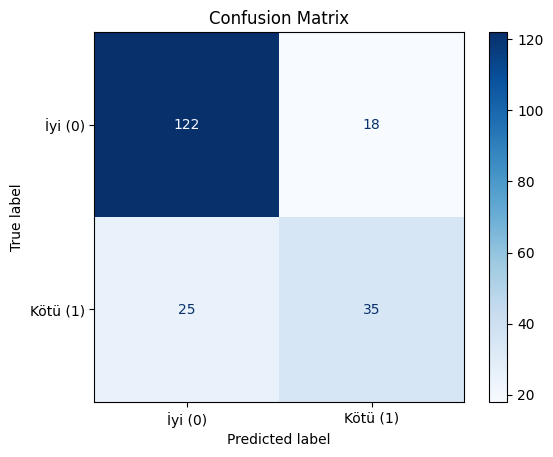

In [53]:
cm = confusion_matrix(y_test,y_pred)
disp = ConfusionMatrixDisplay(confusion_matrix=cm,display_labels=["İyi (0)","Kötü (1)"])
disp.plot(cmap=plt.cm.Blues)
plt.title("Confusion Matrix")
plt.show()

In [54]:
print("Accuracy:", accuracy_score(y_test,y_pred))
print("Precision:", precision_score(y_test,y_pred))
print("Recall:", recall_score(y_test,y_pred))
print("F1 Score:", f1_score(y_test,y_pred))
print("AUC:", roc_auc_score(y_test,y_proba))
print(classification_report(y_test,y_pred))

Accuracy: 0.785
Precision: 0.660377358490566
Recall: 0.5833333333333334
F1 Score: 0.6194690265486725
AUC: 0.7999999999999999
              precision    recall  f1-score   support

           0       0.83      0.87      0.85       140
           1       0.66      0.58      0.62        60

    accuracy                           0.79       200
   macro avg       0.75      0.73      0.73       200
weighted avg       0.78      0.79      0.78       200



#### SVM

In [55]:
from sklearn.svm import SVC

In [56]:
svm_linear = SVC(kernel="linear",C=1.0,probability=True,random_state=42)
svm_linear.fit(X_train_scaled,y_train)

y_pred_linear = svm_linear.predict(X_test_scaled)
y_proba_linear = svm_linear.predict_proba(X_test_scaled)[:,1]

print("Toplam destek vektörü sayısı:", svm_linear.n_support_.sum())
print("support_vectors_:", svm_linear.support_vectors_.shape)

Toplam destek vektörü sayısı: 425
support_vectors_: (425, 48)


In [57]:
print("Accuracy:", accuracy_score(y_test,y_pred_linear))
print("Precision:", precision_score(y_test,y_pred_linear))
print("Recall:", recall_score(y_test,y_pred_linear))
print("F1 Score:", f1_score(y_test,y_pred_linear))
print("AUC:", roc_auc_score(y_test,y_proba_linear))
print(classification_report(y_test,y_pred_linear))

Accuracy: 0.76
Precision: 0.625
Recall: 0.5
F1 Score: 0.5555555555555556
AUC: 0.7717857142857144
              precision    recall  f1-score   support

           0       0.80      0.87      0.84       140
           1       0.62      0.50      0.56        60

    accuracy                           0.76       200
   macro avg       0.71      0.69      0.70       200
weighted avg       0.75      0.76      0.75       200



In [58]:
svm_rbf = SVC(kernel="rbf",C=1.0,gamma="scale",probability=True,random_state=42)
svm_rbf.fit(X_train_scaled,y_train)

y_pred_rbf = svm_rbf.predict(X_test_scaled)
y_proba_rbf = svm_rbf.predict_proba(X_test_scaled)[:,1]

In [59]:
print("Accuracy:", accuracy_score(y_test,y_pred_rbf))
print("Precision:", precision_score(y_test,y_pred_rbf))
print("Recall:", recall_score(y_test,y_pred_rbf))
print("F1 Score:", f1_score(y_test,y_pred_rbf))
print("AUC:", roc_auc_score(y_test,y_proba_rbf))

Accuracy: 0.795
Precision: 0.8064516129032258
Recall: 0.4166666666666667
F1 Score: 0.5494505494505495
AUC: 0.7929166666666666


#### GridSearch ile parametre arayalım

In [60]:
from sklearn.model_selection import GridSearchCV

param_grid = {
    "C":[0.1,1,10,100],
    "gamma":[1,0.1,0.01,0.001],
    "kernel":["rbf"]
}

grid_search = GridSearchCV(SVC(probability=True,random_state=42),param_grid,cv=5,scoring="f1",n_jobs=-1)
grid_search.fit(X_train_scaled,y_train)
print("En iyi parametreler:", grid_search.best_params_)
print("En iyi skor:", grid_search.best_score_)

En iyi parametreler: {'C': 10, 'gamma': 0.01, 'kernel': 'rbf'}
En iyi skor: 0.5417356213345453


In [61]:
svm_best = grid_search.best_estimator_

y_pred_best = svm_best.predict(X_test_scaled)
y_proba_best = svm_best.predict_proba(X_test_scaled)[:,1]

print("Accuracy:", accuracy_score(y_test,y_pred_best))
print("Precision:", precision_score(y_test,y_pred_best))
print("Recall:", recall_score(y_test,y_pred_best))
print("F1 Score:", f1_score(y_test,y_pred_best))
print("AUC:", roc_auc_score(y_test,y_proba_best))

Accuracy: 0.775
Precision: 0.6363636363636364
Recall: 0.5833333333333334
F1 Score: 0.6086956521739131
AUC: 0.803095238095238
